# 02 · Data Quality

Before measuring anything, we need to know which numbers can be trusted. This notebook:

1. validates the raw data (one row per city per day, no impossible values),
2. measures how much data each city has, and when,
3. investigates a suspicious result: **Ahmedabad's AQI looks worse than Delhi's**,
4. records every cleaning decision so the later analysis is reproducible.

The cleaning code lives in `src/air_quality/`, so the same rules apply everywhere and are covered by tests.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from air_quality import config, data, events, lockdown, plots, quality

plots.set_style()
pd.set_option("display.precision", 2)
FIG = config.FIGURES_DIR
TABLES = config.TABLES_DIR
TABLES.mkdir(parents=True, exist_ok=True)

## 1. Load and validate

`load_raw` parses dates and raises an error if any City/Date pair is duplicated, a column is missing, or a concentration is negative.

In [2]:
raw = data.load_raw()
print(f"{len(raw):,} rows · {raw['City'].nunique()} cities · "
      f"{raw['Date'].min():%d %b %Y} to {raw['Date'].max():%d %b %Y}")
raw.head()

29,531 rows · 26 cities · 01 Jan 2015 to 01 Jul 2020


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


## 2. How much data is missing?

Share of rows with no value, per pollutant:

In [3]:
missing = raw[[*config.POLLUTANTS, "AQI"]].isna().mean().sort_values(ascending=False)
(missing * 100).round(1).to_frame("% missing")

,% missing
Xylene,61.3
PM10,37.7
NH3,35.0
Toluene,27.2
Benzene,19.0
AQI,15.9
PM2.5,15.6
NOx,14.2
O3,13.6
SO2,13.1


Missing *rows* matter too: most cities' monitoring started years after 2015. The share of **calendar days** with a PM2.5 reading shows this clearly (`quality.coverage` counts days with no row as missing):

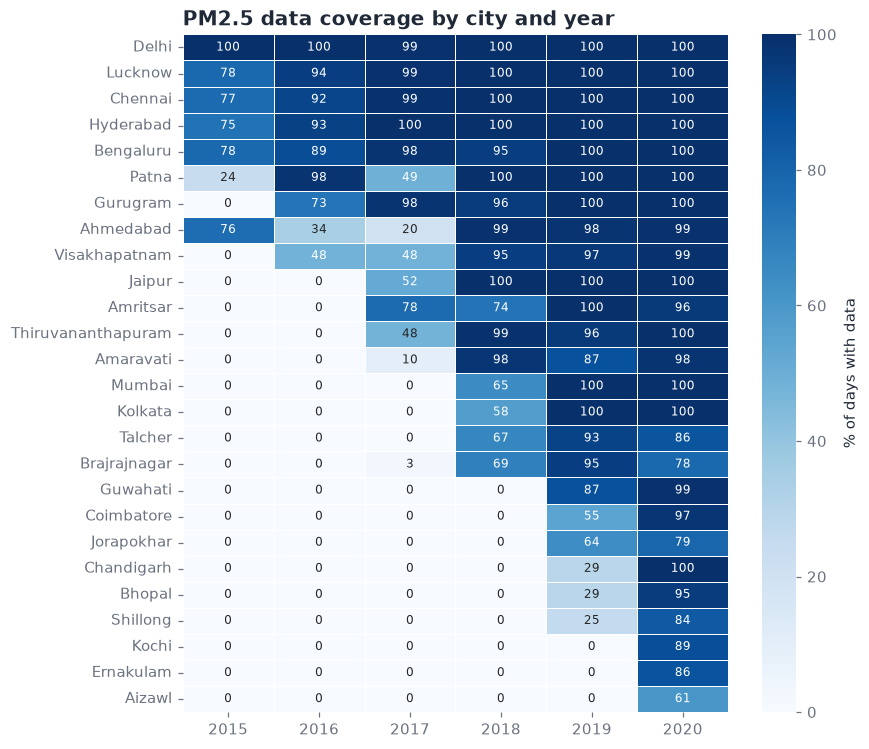

In [4]:
pm25_coverage = quality.coverage_by_year(raw, "PM2.5")
plots.coverage_heatmap(pm25_coverage, "PM2.5 data coverage by city and year",
                       FIG / "01_pm25_coverage.png");

**Takeaways**

- Only Delhi has near-complete PM2.5 data for all six years. Most cities have usable data only from 2018 or 2019.
- Xylene, PM10 and NH3 are missing so often that they are not used in this analysis.
- Any comparison between years must therefore check coverage **for the specific window being compared**. Every analysis here requires at least 80% of days (`config.MIN_COVERAGE`).

## 3. Investigating an anomaly: is Ahmedabad really more polluted than Delhi?

Ranking cities by median AQI puts Ahmedabad first, ahead of Delhi. That contradicts everything known about Indian air quality, so before believing it we compare the pollutants that make up the AQI.

In [5]:
ranking = raw.groupby("City")[["AQI", "PM2.5", "NO2", "CO"]].median()
ranking.sort_values("AQI", ascending=False).head(6)

,AQI,PM2.5,NO2,CO
City,,,,
Ahmedabad,384.5,58.37,47.19,16.24
Delhi,257.0,94.62,47.15,1.24
Patna,215.0,91.12,27.71,1.38
Gurugram,208.0,90.15,19.36,0.75
Lucknow,198.0,86.09,28.15,1.37
Jorapokhar,133.0,60.69,9.36,0.35


Ahmedabad has *less* PM2.5 than Delhi, Patna, Gurugram or Lucknow, but a median CO about **13x higher than Delhi's**. India's AQI is the worst of the individual pollutant sub-indices, so one faulty CO sensor can push the whole AQI up. Over time:

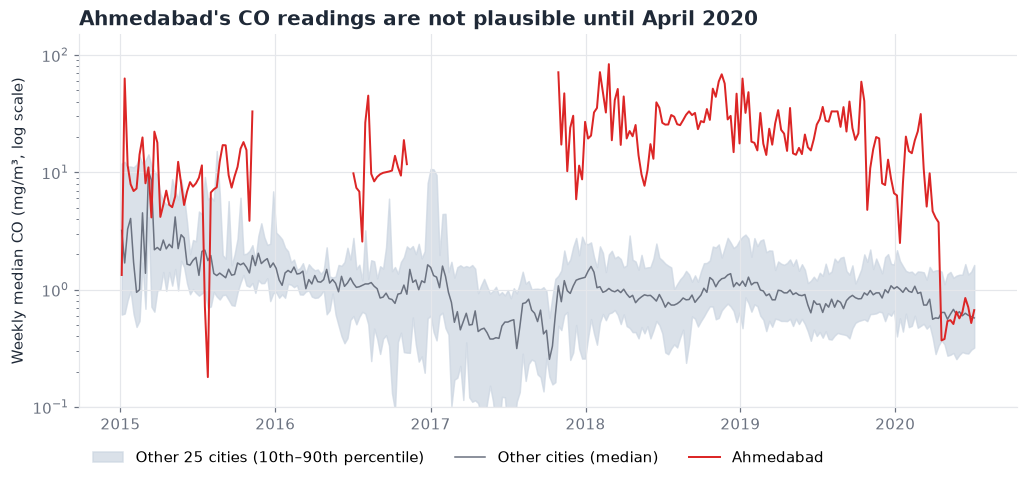

In [6]:
plots.co_anomaly(raw, FIG / "02_ahmedabad_co_anomaly.png");

In [7]:
co = raw[raw["City"] == "Ahmedabad"].set_index("Date")["CO"]
print("Ahmedabad median CO, 2018-2019:", round(co["2018":"2019"].median(), 1), "mg/m³")
print("Ahmedabad median CO, May-June 2020:", round(co["2020-05":"2020-06"].median(), 2), "mg/m³")
print("All other cities, whole period:",
      round(raw.loc[raw["City"] != "Ahmedabad", "CO"].median(), 2), "mg/m³")
co["2020-03-29":"2020-05-03"].resample("W").median().round(2).to_frame("weekly median CO")

Ahmedabad median CO, 2018-2019: 25.9 mg/m³
Ahmedabad median CO, May-June 2020: 0.62 mg/m³
All other cities, whole period: 0.86 mg/m³


,weekly median CO
Date,
2020-03-29,3.08
2020-04-05,4.11
2020-04-12,3.75
2020-04-19,0.37
2020-04-26,0.38
2020-05-03,0.54


For years Ahmedabad's CO sits 10-40x above every other city, then drops by about 10x **within a single week in mid-April 2020**, to a level matching other cities. Real emissions do not behave like that. A sensor fault, recalibration or change in reporting units is far more likely.

**Decision:** Ahmedabad's CO, AQI and AQI_Bucket values are removed (`config.KNOWN_ISSUES`). Its PM2.5 and NO₂ readings look normal and are kept.

**Wider lesson:** the analysis uses individual pollutants (PM2.5, NO₂, ...) rather than AQI, because a composite index can hide exactly this kind of sensor problem.

## 4. Extreme values

The highest daily PM2.5 readings:

In [8]:
raw.nlargest(10, "PM2.5")[["City", "Date", "PM2.5", "PM10", "AQI"]]

,City,Date,PM2.5,PM10,AQI
13041,Gurugram,2017-08-29,949.99,NaN,NaN
25729,Shillong,2019-09-03,917.77,985.00,NaN
14156,Guwahati,2019-05-04,916.67,1000.00,NaN
12504,Gurugram,2016-03-10,914.94,NaN,676.0
25728,Shillong,2019-09-02,914.64,985.00,NaN
12511,Gurugram,2016-03-17,894.75,NaN,NaN
3143,Amritsar,2017-05-08,868.66,116.29,110.0
13011,Gurugram,2017-07-30,858.73,NaN,482.0
3145,Amritsar,2017-05-10,832.80,145.53,NaN
12990,Gurugram,2017-07-09,821.42,NaN,529.0


These are **not** Delhi's famous winter smog days. The ten highest readings are almost all implausible:

- Gurugram at 820-950 µg/m³ in **July and August**, the monsoon, when rain keeps air cleanest;
- **Shillong**, a clean hill city, at over 900 µg/m³;
- Amritsar at 869 µg/m³ PM2.5 while PM10 reads only 116. That is **physically impossible**: PM2.5 particles are a subset of PM10, so PM2.5 can never exceed PM10.

Many values sit just under 1,000, which suggests sensors hitting the top of their range. The PM2.5-vs-PM10 rule gives an objective check wherever both were measured:

In [9]:
both = raw.dropna(subset=["PM2.5", "PM10"])
impossible = both["PM2.5"] > both["PM10"] * config.PM25_PM10_TOLERANCE
print(f"PM2.5 more than {config.PM25_PM10_TOLERANCE - 1:.0%} above PM10: "
      f"{impossible.sum()} of {len(both):,} days ({impossible.mean():.1%})")
both[impossible].groupby("City").size().sort_values(ascending=False).head(8).to_frame("days")

PM2.5 more than 10% above PM10: 199 of 17,632 days (1.1%)


,days
City,
Bengaluru,50
Chennai,33
Hyderabad,28
Talcher,17
Shillong,13
Delhi,13
Amritsar,11
Jaipur,10


**Decision:** PM2.5 is removed on days where it exceeds PM10 by more than 10% (the margin allows for normal measurement noise).

Extremes on days *without* a PM10 reading can't be checked. Some are real (November in Delhi), some are almost certainly faults (Gurugram in August). Rather than deleting values by guesswork, they are kept, and every analysis summarises with **medians**, which a handful of extreme days can't distort. Notebook 03 shows how much the results move if means are used instead.

## 5. Save the clean dataset

In [10]:
clean = data.load_clean()
config.PROCESSED_DATA.parent.mkdir(parents=True, exist_ok=True)
clean.to_csv(config.PROCESSED_DATA, index=False)
checked = ["PM2.5", "CO", "AQI"]
removed = raw[checked].notna().sum() - clean[checked].notna().sum()
print(f"Saved {config.PROCESSED_DATA.name}: {len(clean):,} rows")
removed.to_frame("values removed")

Saved city_day_clean.csv: 29,531 rows


,values removed
PM2.5,199
CO,1400
AQI,1334


## Decisions log

| Decision | Reason |
|---|---|
| Remove Ahmedabad CO, AQI, AQI_Bucket | Implausible CO readings for years, with an abrupt 10x drop in April 2020 |
| Remove PM2.5 where it exceeds PM10 by more than 10% | Physically impossible (PM2.5 is part of PM10) |
| Use pollutants, not AQI | AQI is a composite and can hide sensor faults |
| Require 80% of calendar days in every compared window | Most cities have large gaps; comparisons must use like-for-like data |
| Keep other extreme values; use medians | Where PM10 is missing, real smog and sensor faults can't be reliably separated |
| Drop Xylene, PM10, NH3 from analysis | Missing in 35-61% of rows |